In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [2]:
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Размер датасета:", df.shape)
print("\nПервые 5 строк:")
display(df.head())

print("\nНазвания столбцов:")
print(df.columns.tolist())

Размер датасета: (7043, 21)

Первые 5 строк:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Названия столбцов:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Типы данных:")
print(df.dtypes)

print("\nКоличество пропусков:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nКоличество дубликатов:", df.duplicated().sum())

print("\nРаспределение целевого признака:")
print(df["Churn"].value_counts())

Типы данных:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

Количество пропусков:
TotalCharges      11
gender             0
SeniorCitizen      0
Partner            0
customerID         0
Dependents         0
tenure             0
MultipleLines      0
PhoneService       0
OnlineSecurity     0
dtype: int64

Количество дубликатов: 0

Распределение целевого признака:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [4]:
X = df.drop(columns=["Churn", "customerID"])
y = (df["Churn"] == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

print("\nКлиенты в обучающей выборке:")
print(y_train.value_counts())

print("\nКлиенты в тестовой выборке:")
print(y_test.value_counts())

Обучающая выборка: (5634, 19)
Тестовая выборка: (1409, 19)

Клиенты в обучающей выборке:
Churn
0    4139
1    1495
Name: count, dtype: int64

Клиенты в тестовой выборке:
Churn
0    1035
1     374
Name: count, dtype: int64


In [5]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Числовые признаки:", numeric_features)
print("\nКатегориальные признаки:", categorical_features)

Числовые признаки: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Категориальные признаки: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [6]:
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

In [7]:
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

tree_model.fit(X_train, y_train)

tree_results = evaluate_model(tree_model, X_test, y_test)

print("Результаты дерева решений:")
for metric, value in tree_results.items():
    print(f"{metric}: {value:.4f}")

Результаты дерева решений:
Accuracy: 0.7289
Precision: 0.4896
Recall: 0.5053
F1: 0.4974
ROC-AUC: 0.6573


In [8]:
default_rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

default_rf_model.fit(X_train, y_train)

default_rf_results = evaluate_model(default_rf_model, X_test, y_test)

print("Результаты случайного леса по умолчанию:")
for metric, value in default_rf_results.items():
    print(f"{metric}: {value:.4f}")

print(
    "\nКоличество деревьев:",
    default_rf_model.named_steps["model"].n_estimators
)

Результаты случайного леса по умолчанию:
Accuracy: 0.7779
Precision: 0.6034
Recall: 0.4759
F1: 0.5321
ROC-AUC: 0.8162

Количество деревьев: 100


,Accuracy,Precision,Recall,F1,ROC-AUC
Decision Tree,0.7289,0.4896,0.5053,0.4974,0.6573
Random Forest Default,0.7779,0.6034,0.4759,0.5321,0.8162


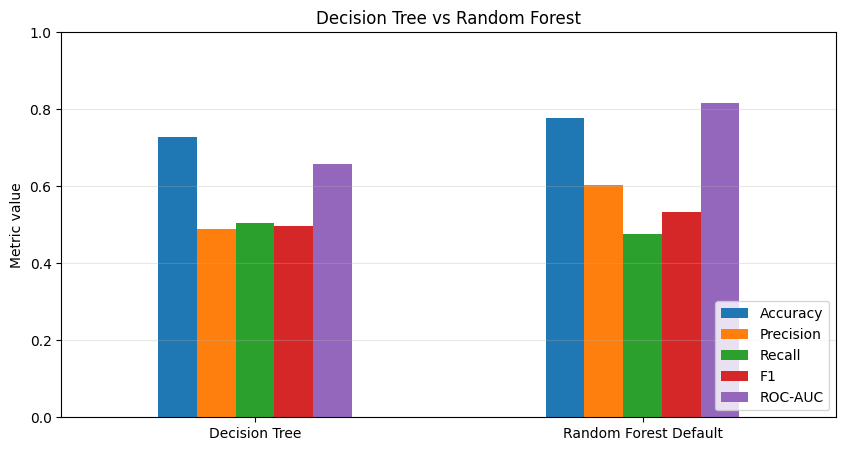

In [9]:
comparison = pd.DataFrame(
    [tree_results, default_rf_results],
    index=["Decision Tree", "Random Forest Default"]
)

display(comparison.round(4))

comparison.plot(kind="bar", figsize=(10, 5))
plt.title("Decision Tree vs Random Forest")
plt.ylabel("Metric value")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [10]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        oob_score=True
    ))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 4]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Лучшие параметры:")
print(grid_search.best_params_)

print("\nЛучший средний F1 на кросс-валидации:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Лучшие параметры:
{'model__max_depth': 10, 'model__min_samples_leaf': 4, 'model__n_estimators': 200}

Лучший средний F1 на кросс-валидации:
0.584


In [11]:
best_rf_model = grid_search.best_estimator_

best_rf_results = evaluate_model(
    best_rf_model,
    X_test,
    y_test
)

final_comparison = pd.DataFrame(
    [
        tree_results,
        default_rf_results,
        best_rf_results
    ],
    index=[
        "Decision Tree",
        "Random Forest Default",
        "Random Forest Tuned"
    ]
)

display(final_comparison.round(4))

print(
    "\nКоличество деревьев в настроенном лесу:",
    best_rf_model.named_steps["model"].n_estimators
)

print(
    "OOB score настроенного леса:",
    round(best_rf_model.named_steps["model"].oob_score_, 4)
)

,Accuracy,Precision,Recall,F1,ROC-AUC
Decision Tree,0.7289,0.4896,0.5053,0.4974,0.6573
Random Forest Default,0.7779,0.6034,0.4759,0.5321,0.8162
Random Forest Tuned,0.8027,0.6678,0.5107,0.5788,0.8412



Количество деревьев в настроенном лесу: 200
OOB score настроенного леса: 0.8026


Важность исходных признаков:


,Importance
Feature,
Contract,0.1524
tenure,0.1484
TotalCharges,0.1150
OnlineSecurity,0.0850
InternetService,0.0784
MonthlyCharges,0.0740
TechSupport,0.0699
PaymentMethod,0.0631
OnlineBackup,0.0342


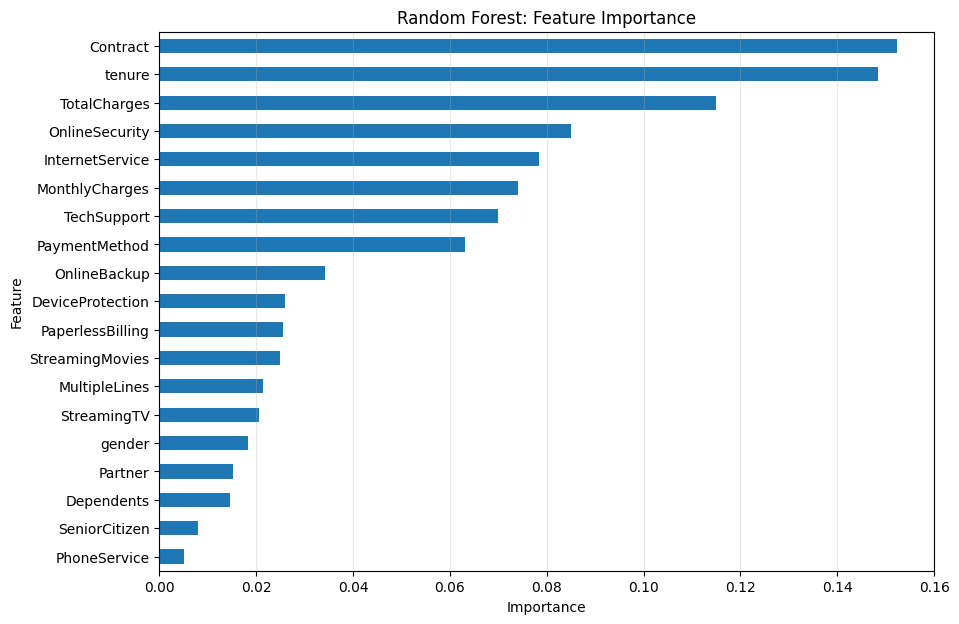

In [12]:
fitted_preprocessor = best_rf_model.named_steps["preprocessor"]
rf = best_rf_model.named_steps["model"]

encoded_names = fitted_preprocessor.get_feature_names_out()
importances = rf.feature_importances_

importance_df = pd.DataFrame({
    "EncodedFeature": encoded_names,
    "Importance": importances
})

def get_original_feature(encoded_name):
    name = encoded_name.split("__", 1)[-1]

    if name in X.columns:
        return name

    matches = [
        col for col in X.columns
        if name.startswith(col + "_")
    ]

    if matches:
        return max(matches, key=len)

    return name

importance_df["Feature"] = importance_df["EncodedFeature"].apply(
    get_original_feature
)

grouped_importance = (
    importance_df.groupby("Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

print("Важность исходных признаков:")
display(grouped_importance.to_frame().round(4))

grouped_importance.sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Random Forest: Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.show()

In [13]:
features_to_remove = grouped_importance.nsmallest(3).index.tolist()

print("Признаки для удаления:")
print(features_to_remove)

X_train_reduced = X_train.drop(columns=features_to_remove)
X_test_reduced = X_test.drop(columns=features_to_remove)

numeric_reduced = [
    col for col in numeric_features
    if col not in features_to_remove
]

categorical_reduced = [
    col for col in categorical_features
    if col not in features_to_remove
]

numeric_transformer_reduced = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_reduced = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_reduced = ColumnTransformer([
    ("num", numeric_transformer_reduced, numeric_reduced),
    ("cat", categorical_transformer_reduced, categorical_reduced)
])

best_params = grid_search.best_params_

reduced_rf_model = Pipeline([
    ("preprocessor", preprocessor_reduced),
    ("model", RandomForestClassifier(
        n_estimators=best_params["model__n_estimators"],
        max_depth=best_params["model__max_depth"],
        min_samples_leaf=best_params["model__min_samples_leaf"],
        random_state=42,
        n_jobs=-1
    ))
])

reduced_rf_model.fit(X_train_reduced, y_train)

reduced_rf_results = evaluate_model(
    reduced_rf_model,
    X_test_reduced,
    y_test
)

feature_experiment = pd.DataFrame(
    [best_rf_results, reduced_rf_results],
    index=["All Features", "Without 3 Least Important"]
)

display(feature_experiment.round(4))

Признаки для удаления:
['PhoneService', 'SeniorCitizen', 'Dependents']


,Accuracy,Precision,Recall,F1,ROC-AUC
All Features,0.8027,0.6678,0.5107,0.5788,0.8412
Without 3 Least Important,0.8027,0.6633,0.5214,0.5838,0.8416


,Accuracy,Precision,Recall,F1,ROC-AUC
Decision Tree,0.7289,0.4896,0.5053,0.4974,0.6573
Random Forest Default,0.7779,0.6034,0.4759,0.5321,0.8162
Random Forest Tuned,0.8027,0.6678,0.5107,0.5788,0.8412
Random Forest Reduced,0.8027,0.6633,0.5214,0.5838,0.8416


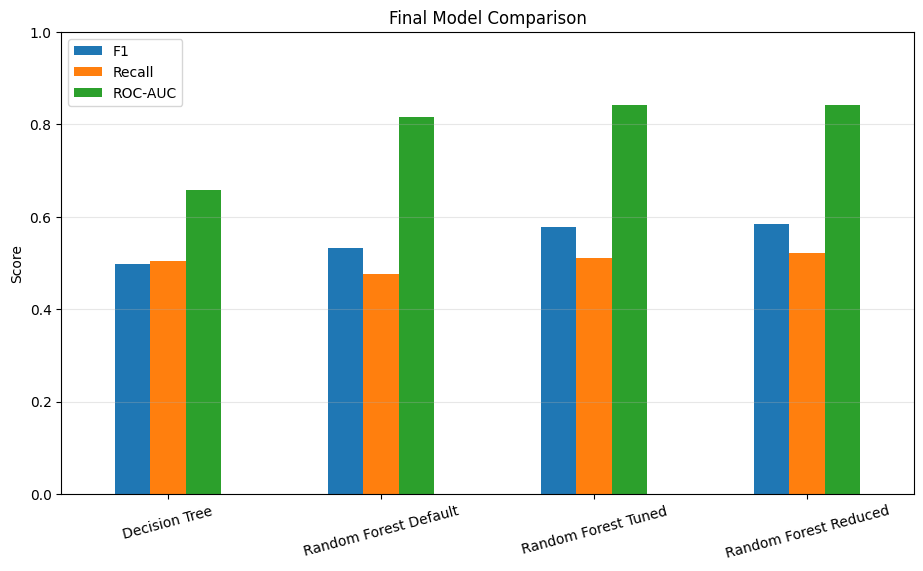

In [14]:
summary = pd.DataFrame(
    [
        tree_results,
        default_rf_results,
        best_rf_results,
        reduced_rf_results
    ],
    index=[
        "Decision Tree",
        "Random Forest Default",
        "Random Forest Tuned",
        "Random Forest Reduced"
    ]
)

display(summary.round(4))

summary[["F1", "Recall", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Final Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.show()